<a href="https://colab.research.google.com/github/Abraham-on-del/AF3_Pndeulo_Robot/blob/main/AF3_Simulacion_Pendulo_Robot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

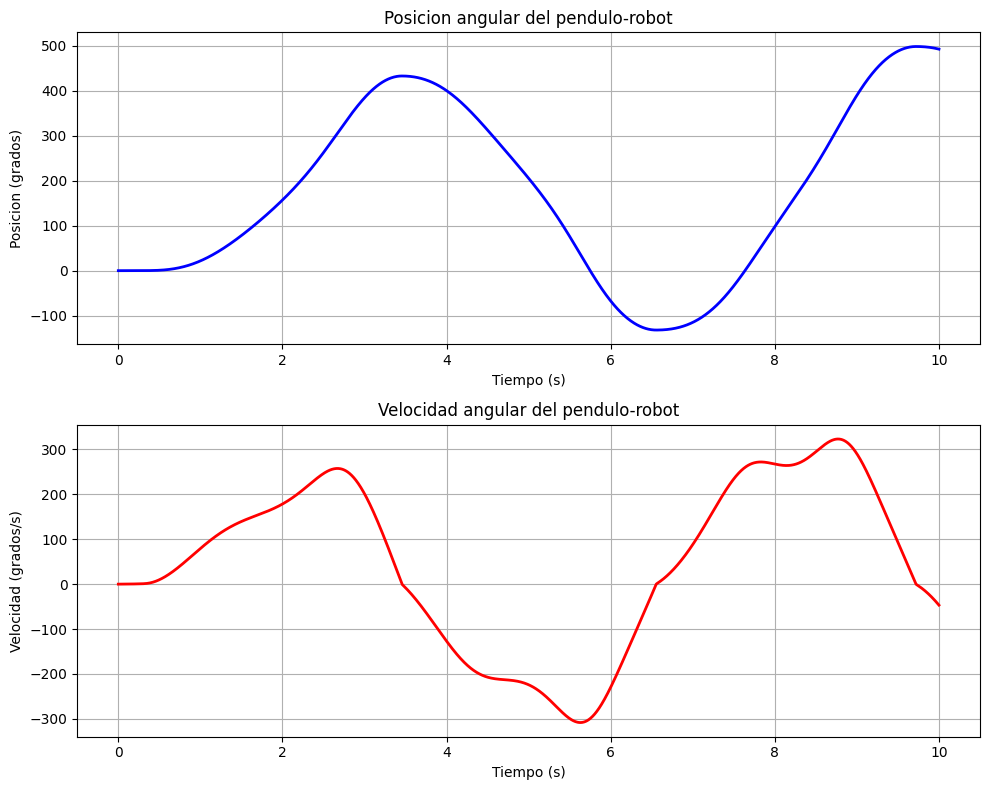

RESULTADOS DE LA SIMULACION
Posicion final: 492.7000 grados
Velocidad final: -46.7499 grados/s


In [5]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# AF3 - SIMULACION PENDULO-ROBOT


# 1. PARAMETROS DEL SISTEMA
m = 5.0
g = 9.81
lc = 0.01
Ir = 0.16
b = 0.14
fc = 0.45

# Inercia equivalente
J = m * lc**2 + Ir

# 2. TORQUE APLICADO POR EL MOTOR
def torque(t):
    return 1.5 * np.sin(t)

# 3. ECUACIONES EN ESPACIO DE ESTADOS
def modelo(t, x):
    x1 = x[0]  # Posicion angular (rad)
    x2 = x[1]  # Velocidad angular (rad/s)

    tau = torque(t)

    dx1 = x2
    dx2 = (
        tau
        - b * x2
        - fc * np.tanh(100 * x2)
        - m * g * lc * np.sin(x1)
    ) / J

    return [dx1, dx2]

# 4. CONDICIONES INICIALES
x0 = [0.0, 0.0]

# 5. TIEMPO DE SIMULACION
ti = 0
tf = 10
t = np.linspace(ti, tf, 2001)

# 6. SOLUCION NUMERICA
sol = solve_ivp(
    modelo,
    (ti, tf),
    x0,
    t_eval=t,
    method="RK45",
    rtol=1e-8,
    atol=1e-10,
    max_step=0.005
)

# 7. RESULTADOS
posicion = np.rad2deg(sol.y[0])
velocidad = np.rad2deg(sol.y[1])

# 8. GRAFICAS
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

# Posicion angular
ax[0].plot(sol.t, posicion, color="blue", linewidth=2)
ax[0].set_title("Posicion angular del pendulo-robot")
ax[0].set_xlabel("Tiempo (s)")
ax[0].set_ylabel("Posicion (grados)")
ax[0].grid(True)

# Velocidad angular
ax[1].plot(sol.t, velocidad, color="red", linewidth=2)
ax[1].set_title("Velocidad angular del pendulo-robot")
ax[1].set_xlabel("Tiempo (s)")
ax[1].set_ylabel("Velocidad (grados/s)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

# 9. VALORES FINALES
print("RESULTADOS DE LA SIMULACION")
print(f"Posicion final: {posicion[-1]:.4f} grados")
print(f"Velocidad final: {velocidad[-1]:.4f} grados/s")
